# EMQA_L6_bat_region

**Regional battery arbitrage: mean daily revenue (EUR per MW) of a 2h, 1 MW battery with perfect foresight on the day-ahead prices of Romania, Bulgaria and Hungary, monthly, 2024-01 to 2026-10, and the monthly mean output of the Romanian and Bulgarian battery fleets as reported to ENTSO-E. Prints the revenue of the last 12 months by zone (with Germany-Luxembourg) and the correlation of daily revenues between Romania and its neighbours.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_bat_region/EMQA_L6_bat_region.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Battery of 1 MW and E = 1, 2 or 4 MWh, round-trip efficiency 85%, at most one full cycle a day, empty at the start and end of each delivery day (Cole & Karmakar, 2023, NREL). For each day a linear programme (scipy, HiGHS) maximises sum_t p_t (d_t - c_t) dt_t. About 1 ms per day, so the whole computation runs in well under a minute.

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def day_groups(zone, start=None, end=None, hourly=False):
    """Prices per CET delivery day (complete days only: 23/24/25 hours or 92/96/100 quarter-hours)."""
    s = PX[[zone, 'dur']]
    if start is not None:
        s = s[s.index >= start]
    if end is not None:
        s = s[s.index < end]
    if hourly:
        s = s.groupby(hfloor(s.index)).agg({zone: 'mean', 'dur': 'sum'})
    out = {}
    for dd, g in s.groupby(s.index.tz_localize(None).normalize()):
        if g[zone].notna().all() and abs(g['dur'].sum() - round(g['dur'].sum())) < 1e-9 and round(g['dur'].sum()) in (23, 24, 25):
            out[dd] = (g[zone].values.astype(float), g['dur'].values.astype(float))
    return out

In [6]:
from scipy import sparse
from scipy.optimize import linprog

ETA, CYCLES, DURS = 0.85, 1.0, (1, 2, 4)   # round-trip efficiency, max cycles per day, hours of storage (NREL 2023 update)


def battery_day(p, dur, E, P=1.0, eta=ETA, cycles=CYCLES):
    """Optimal charge c_t and discharge d_t (MW) of a P-MW / E-MWh battery for one day of prices p_t and interval lengths dur_t (h):
    max sum_t p_t (d_t - c_t) dur_t  s.t.  s_t = s_{t-1} + sqrt(eta) c_t dur_t - d_t dur_t / sqrt(eta),
    0 <= s_t <= E, s_0 = s_T = 0, 0 <= c_t, d_t <= P, sum_t d_t dur_t / sqrt(eta) <= cycles * E.  Linear programme (HiGHS)."""
    n = len(p)
    r = np.sqrt(eta)
    cost = np.concatenate([p * dur, -p * dur, np.zeros(n)])
    Lw = sparse.diags([np.ones(n), -np.ones(n - 1)], [0, -1], format='csr')          # s_t - s_{t-1}
    A_eq = sparse.hstack([-r * sparse.diags(dur), sparse.diags(dur / r), Lw], format='csr')
    A_eq = sparse.vstack([A_eq, sparse.hstack([sparse.csr_matrix((1, 2 * n)), sparse.csr_matrix(([1.0], ([0], [n - 1])), shape=(1, n))])])
    b_eq = np.zeros(n + 1)
    A_ub = sparse.hstack([sparse.csr_matrix((1, n)), sparse.csr_matrix(dur / r), sparse.csr_matrix((1, n))], format='csr')
    bounds = [(0, P)] * (2 * n) + [(0, E)] * n
    res = linprog(cost, A_ub=A_ub, b_ub=[cycles * E], A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
    x = res.x
    return x[:n], x[n:2 * n]


def revenue(p, dur, c, d):
    return float(np.sum(p * (d - c) * dur))


def run_battery(dg, E, forecast=None):
    """Daily revenue (EUR per MW) with perfect foresight, or with the schedule optimised on `forecast` (dict day -> prices)."""
    out = {}
    for day, (p, w) in dg.items():
        if forecast is None:
            c, d = battery_day(p, w, E)
        else:
            f = forecast.get(day)
            if f is None or len(f) != len(p):
                continue
            c, d = battery_day(f, w, E)
        out[day] = revenue(p, w, c, d)
    return pd.Series(out)

In [7]:
T24 = pd.Timestamp('2024-01-01').tz_localize(TZ)
D2 = {z: run_battery(day_groups(z, start=T24), 2) for z in ('RO', 'BG', 'HU')}       # daily revenue, EUR per MW
D2['DE_LU'] = run_battery(day_groups('DE_LU', start=LTM0), 2)
LTM = {z: s[s.index >= LTM0.tz_localize(None)] for z, s in D2.items()}
BMM = {z: D2[z].groupby(D2[z].index.to_period('M')).mean() for z in ('RO', 'BG', 'HU')}

FLEET = {}
for c in ('ro', 'bg'):
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc'], usecols=['timestamp_utc', 'battery'])
    b = g.set_index('timestamp_utc')['battery']
    b.index = b.index.tz_convert(TZ)
    b = b[(b.index >= T24) & (b.index < END_X)]
    FLEET[c.upper()] = b.groupby(b.index.tz_localize(None).to_period('M')).mean()

show_numbers({**{f'bat.reg.{z}': fl(LTM[z].sum() / 1000, 1) for z in ('RO', 'BG', 'HU', 'DE_LU')},
              'bat.corr_ro_bg': fl(pd.concat([LTM['RO'], LTM['BG']], axis=1).dropna().corr().iloc[0, 1], 2),
              'bat.corr_ro_hu': fl(pd.concat([LTM['RO'], LTM['HU']], axis=1).dropna().corr().iloc[0, 1], 2)})

bat.reg.RO                         111.2
bat.reg.BG                         96.4
bat.reg.HU                         117.6
bat.reg.DE_LU                      90.6
bat.corr_ro_bg                     0.8
bat.corr_ro_hu                     0.87


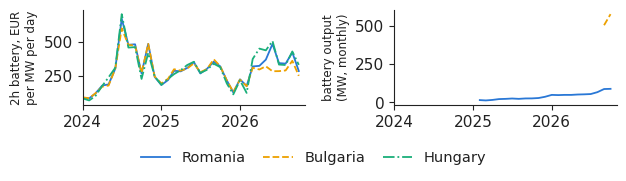

In [8]:
import matplotlib.dates as mdates

fig, axs = plt.subplots(1, 2, figsize=(6.4, 1.9))
for z in ('RO', 'BG', 'HU'):
    s = BMM[z]
    axs[0].plot(s.index.to_timestamp(), s.values, color=PAL[z], ls=ZONE_LS[z], lw=1.3, label=ZN[z])
axs[0].set_ylabel('2h battery, EUR\nper MW per day', fontsize=8.5)
for ax in axs:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.set_xlim(pd.Timestamp('2024-01-01'), END)
for z in ('RO', 'BG'):
    s = FLEET[z].dropna()
    axs[1].plot(s.index.to_timestamp(), s.values, color=PAL[z], ls=ZONE_LS[z], lw=1.3)
axs[1].set_ylabel('battery output\n(MW, monthly)', fontsize=8.5)
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('bat_region.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()